# 📊 Evaluasi Model ENet — Semantic Segmentation

Notebook ini **mengevaluasi model ENet yang sudah dilatih** (tanpa training ulang).

**Konfigurasi (dari `config.json`):** arsitektur ENet, 4 kelas, input 256×512, normalisasi ImageNet, best mIoU 0.9009.

**Output:**
- Tabel per-kelas: Precision, Recall, F1-score, IoU (+ baris Rata-rata)
- Tabel ringkasan: Pixel Accuracy, Mean IoU, Mean Precision, Mean Recall, Mean F1
- Confusion matrix (jumlah & ternormalisasi) + heatmap

> Semua metrik dihitung dari **satu confusion matrix** yang diakumulasi per-piksel.

## 1️⃣ Import & Setup

In [1]:
import os, json, glob
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

try:
    import seaborn as sns
    HAS_SNS = True
except Exception:
    HAS_SNS = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
print('Torch:', torch.__version__)

Device: cuda
Torch: 2.10.0+cu128


## 2️⃣ Muat `config.json`

Mengambil num_classes, ukuran input, dan normalisasi langsung dari file konfigurasi training.

In [2]:
# ---- PATH (sesuaikan dengan dataset Kaggle kamu) ----
MODEL_PATH  = '/kaggle/input/notebooks/ryosukeeh/enet-drva/ENet_Model_DRVA_vLapan/best_model.pth'
CONFIG_PATH = '/kaggle/input/notebooks/ryosukeeh/enet-drva/ENet_Model_DRVA_vLapan/config.json'

# Folder gambar & mask untuk split TEST/VALIDATION
IMAGES_DIR = '/kaggle/input/datasets/ryosukeeh/drva-v7/test/images'
MASKS_DIR  = '/kaggle/input/datasets/ryosukeeh/drva-v7/test/masks'

OUT_DIR = '/kaggle/working'
os.makedirs(OUT_DIR, exist_ok=True)

# ---- Muat config ----
config = {}
if os.path.exists(CONFIG_PATH):
    with open(CONFIG_PATH) as f:
        config = json.load(f)
    print('config.json dimuat:')
    print(json.dumps(config, indent=2))
else:
    print('⚠️  config.json tidak ditemukan, memakai nilai default.')

NUM_CLASSES = int(config.get('num_classes', 4))
IMG_HEIGHT  = int(config.get('img_height', 256))
IMG_WIDTH   = int(config.get('img_width', 512))
INPUT_SIZE  = (IMG_HEIGHT, IMG_WIDTH)  # (H, W)

norm = config.get('normalization', {})
MEAN = norm.get('mean', [0.485, 0.456, 0.406])
STD  = norm.get('std',  [0.229, 0.224, 0.225])

# Nama kelas untuk tabel (urut sesuai index 0..3). Boageh disesuaikan tampilannya.
CLASS_NAMES = config.get('class_names', ['background','drivable_area','pothole','speed_bump'])
# Versi tampilan rapi untuk tabel/heatmap (samakan urutannya!)
DISPLAY_NAMES = ['Background / Non-drivable', 'Drivable area', 'Pothole', 'Speed bump']
if len(DISPLAY_NAMES) != NUM_CLASSES:
    DISPLAY_NAMES = CLASS_NAMES

# Label yang diabaikan saat hitung metrik (mis. void). None kalau tidak ada.
IGNORE_INDEX = None

print('NUM_CLASSES =', NUM_CLASSES, '| INPUT_SIZE =', INPUT_SIZE)
print('MEAN =', MEAN, '| STD =', STD)
print('CLASS_NAMES =', CLASS_NAMES)

config.json dimuat:
{
  "architecture": "ENet",
  "num_classes": 4,
  "class_names": [
    "background",
    "drivable_area",
    "pothole",
    "speed_bump"
  ],
  "img_height": 256,
  "img_width": 512,
  "best_miou": 0.7705,
  "num_epochs": 300,
  "learning_rate": 0.0003,
  "batch_size": 4,
  "normalization": {
    "mean": [
      0.485,
      0.456,
      0.406
    ],
    "std": [
      0.229,
      0.224,
      0.225
    ]
  }
}
NUM_CLASSES = 4 | INPUT_SIZE = (256, 512)
MEAN = [0.485, 0.456, 0.406] | STD = [0.229, 0.224, 0.225]
CLASS_NAMES = ['background', 'drivable_area', 'pothole', 'speed_bump']


## 3️⃣ Arsitektur ENet (sama persis dengan training)

Definisi `InitialBlock`, `BottleNeck`, dan `ENet` ini menggantikan `build_model()`.
Harus identik dengan saat training agar `load_state_dict` cocok.

In [3]:
# ==========================================
# ARSITEKTUR ENET (sama persis dengan training)
# Diadaptasi dari:
# https://github.com/yassouali/pytorch-segmentation/blob/master/models/enet.py
# ==========================================

def initialize_weights(*models):
    """Inisialisasi bobot kaiming untuk Conv2d dan BatchNorm."""
    for model in models:
        for module in model.modules():
            if isinstance(module, nn.Conv2d) or isinstance(module, nn.ConvTranspose2d):
                nn.init.kaiming_normal_(module.weight)
                if module.bias is not None:
                    module.bias.data.zero_()
            elif isinstance(module, nn.BatchNorm2d):
                module.weight.data.fill_(1)
                module.bias.data.zero_()


class InitialBlock(nn.Module):
    """Blok pertama ENet: menggabungkan MaxPool dan Conv untuk efisiensi."""
    def __init__(self, in_channels, use_prelu=True):
        super(InitialBlock, self).__init__()
        self.pool  = nn.MaxPool2d(kernel_size=2, stride=2, ceil_mode=True)
        self.conv  = nn.Conv2d(in_channels, 16 - in_channels, 3, padding=1, stride=2)
        self.bn    = nn.BatchNorm2d(16)
        self.prelu = nn.PReLU(16) if use_prelu else nn.ReLU(inplace=True)

    def forward(self, x):
        x = torch.cat((self.pool(x), self.conv(x)), dim=1)
        x = self.bn(x)
        x = self.prelu(x)
        return x


class BottleNeck(nn.Module):
    """
    Bottleneck ENet yang mendukung:
    - Regular convolution
    - Dilated convolution
    - Asymmetric convolution (1x5 + 5x1)
    - Downsampling (MaxPool + strided conv)
    - Upsampling (MaxUnpool + transposed conv)
    """
    def __init__(self, in_channels, out_channels=None, dilation=1, downsample=False,
                 proj_ratio=4, upsample=False, asymetric=False,
                 regularize=True, p_drop=None, use_prelu=True):
        super(BottleNeck, self).__init__()
        self.pad        = 0
        self.upsample   = upsample
        self.downsample = downsample

        if out_channels is None:
            out_channels = in_channels
        else:
            self.pad = out_channels - in_channels

        if regularize: assert p_drop is not None
        if downsample: assert not upsample
        elif upsample: assert not downsample

        inter_channels = in_channels // proj_ratio

        # ---- Main branch (identity / pool / unpool) ----
        if upsample:
            self.spatil_conv = nn.Conv2d(in_channels, out_channels, 1, bias=False)
            self.bn_up       = nn.BatchNorm2d(out_channels)
            self.unpool      = nn.MaxUnpool2d(kernel_size=2, stride=2)
        elif downsample:
            self.pool = nn.MaxPool2d(kernel_size=2, stride=2, return_indices=True)

        # ---- Bottleneck branch ----
        # 1x1 projection
        self.conv1  = nn.Conv2d(in_channels, inter_channels, 2 if downsample else 1,
                                stride=2 if downsample else 1, bias=False)
        self.bn1    = nn.BatchNorm2d(inter_channels)
        self.prelu1 = nn.PReLU() if use_prelu else nn.ReLU(inplace=True)

        # main conv
        if asymetric:
            self.conv2 = nn.Sequential(
                nn.Conv2d(inter_channels, inter_channels, kernel_size=(1, 5), padding=(0, 2)),
                nn.BatchNorm2d(inter_channels),
                nn.PReLU() if use_prelu else nn.ReLU(inplace=True),
                nn.Conv2d(inter_channels, inter_channels, kernel_size=(5, 1), padding=(2, 0)),
            )
        elif upsample:
            self.conv2 = nn.ConvTranspose2d(inter_channels, inter_channels,
                                            kernel_size=3, padding=1,
                                            output_padding=1, stride=2, bias=False)
        else:
            self.conv2 = nn.Conv2d(inter_channels, inter_channels, 3,
                                   padding=dilation, dilation=dilation, bias=False)

        self.bn2    = nn.BatchNorm2d(inter_channels)
        self.prelu2 = nn.PReLU() if use_prelu else nn.ReLU(inplace=True)

        # 1x1 expansion
        self.conv3  = nn.Conv2d(inter_channels, out_channels, 1, bias=False)
        self.bn3    = nn.BatchNorm2d(out_channels)
        self.prelu3 = nn.PReLU() if use_prelu else nn.ReLU(inplace=True)

        self.regularizer = nn.Dropout2d(p_drop) if regularize else None
        self.prelu_out   = nn.PReLU() if use_prelu else nn.ReLU(inplace=True)

    def forward(self, x, indices=None, output_size=None):
        identity = x

        if self.upsample:
            assert (indices is not None) and (output_size is not None)
            identity = self.bn_up(self.spatil_conv(identity))
            if identity.size() != indices.size():
                pad = (indices.size(3) - identity.size(3), 0,
                       indices.size(2) - identity.size(2), 0)
                identity = F.pad(identity, pad, "constant", 0)
            identity = self.unpool(identity, indices=indices)
        elif self.downsample:
            identity, idx = self.pool(identity)
            if self.pad > 0:
                extras   = torch.zeros((identity.size(0), self.pad,
                                        identity.size(2), identity.size(3)),
                                       device=x.device)
                identity = torch.cat((identity, extras), dim=1)

        # Bottleneck
        x = self.prelu1(self.bn1(self.conv1(x)))
        x = self.conv2(x)
        x = self.prelu2(self.bn2(x))
        x = self.prelu3(self.bn3(self.conv3(x)))

        if self.regularizer is not None:
            x = self.regularizer(x)

        # Align spatial size jika ada perbedaan 1 pixel
        if identity.size() != x.size():
            pad = (identity.size(3) - x.size(3), 0,
                   identity.size(2) - x.size(2), 0)
            x = F.pad(x, pad, "constant", 0)

        x = self.prelu_out(x + identity)

        if self.downsample:
            return x, idx
        return x


class ENet(nn.Module):
    """
    ENet: A Deep Neural Network Architecture for Real-Time Semantic Segmentation
    Paper: https://arxiv.org/abs/1606.02147
    """
    def __init__(self, num_classes, in_channels=3):
        super(ENet, self).__init__()

        self.initial = InitialBlock(in_channels)

        # Stage 1 - Encoder
        self.bottleneck10 = BottleNeck(16,  64,  downsample=True, p_drop=0.01)
        self.bottleneck11 = BottleNeck(64,        p_drop=0.01)
        self.bottleneck12 = BottleNeck(64,        p_drop=0.01)
        self.bottleneck13 = BottleNeck(64,        p_drop=0.01)
        self.bottleneck14 = BottleNeck(64,        p_drop=0.01)

        # Stage 2 - Encoder
        self.bottleneck20 = BottleNeck(64,  128, downsample=True, p_drop=0.1)
        self.bottleneck21 = BottleNeck(128,      p_drop=0.1)
        self.bottleneck22 = BottleNeck(128,      dilation=2,  p_drop=0.1)
        self.bottleneck23 = BottleNeck(128,      asymetric=True, p_drop=0.1)
        self.bottleneck24 = BottleNeck(128,      dilation=4,  p_drop=0.1)
        self.bottleneck25 = BottleNeck(128,      p_drop=0.1)
        self.bottleneck26 = BottleNeck(128,      dilation=8,  p_drop=0.1)
        self.bottleneck27 = BottleNeck(128,      asymetric=True, p_drop=0.1)
        self.bottleneck28 = BottleNeck(128,      dilation=16, p_drop=0.1)

        # Stage 3 - Encoder (ulang stage 2 tanpa downsample)
        self.bottleneck31 = BottleNeck(128,      p_drop=0.1)
        self.bottleneck32 = BottleNeck(128,      dilation=2,  p_drop=0.1)
        self.bottleneck33 = BottleNeck(128,      asymetric=True, p_drop=0.1)
        self.bottleneck34 = BottleNeck(128,      dilation=4,  p_drop=0.1)
        self.bottleneck35 = BottleNeck(128,      p_drop=0.1)
        self.bottleneck36 = BottleNeck(128,      dilation=8,  p_drop=0.1)
        self.bottleneck37 = BottleNeck(128,      asymetric=True, p_drop=0.1)
        self.bottleneck38 = BottleNeck(128,      dilation=16, p_drop=0.1)

        # Stage 4 - Decoder
        self.bottleneck40 = BottleNeck(128, 64, upsample=True, p_drop=0.1, use_prelu=False)
        self.bottleneck41 = BottleNeck(64,       p_drop=0.1, use_prelu=False)
        self.bottleneck42 = BottleNeck(64,       p_drop=0.1, use_prelu=False)

        # Stage 5 - Decoder
        self.bottleneck50 = BottleNeck(64, 16, upsample=True, p_drop=0.1, use_prelu=False)
        self.bottleneck51 = BottleNeck(16,      p_drop=0.1, use_prelu=False)

        # Stage 6 - Final Upsample ke resolusi asli
        self.fullconv = nn.ConvTranspose2d(16, num_classes, kernel_size=3, padding=1,
                                          output_padding=1, stride=2, bias=False)

        initialize_weights(self)

    def forward(self, x):
        # Initial block
        x = self.initial(x)

        # Stage 1
        sz1 = x.size()
        x, indices1 = self.bottleneck10(x)
        x = self.bottleneck11(x)
        x = self.bottleneck12(x)
        x = self.bottleneck13(x)
        x = self.bottleneck14(x)

        # Stage 2
        sz2 = x.size()
        x, indices2 = self.bottleneck20(x)
        x = self.bottleneck21(x)
        x = self.bottleneck22(x)
        x = self.bottleneck23(x)
        x = self.bottleneck24(x)
        x = self.bottleneck25(x)
        x = self.bottleneck26(x)
        x = self.bottleneck27(x)
        x = self.bottleneck28(x)

        # Stage 3
        x = self.bottleneck31(x)
        x = self.bottleneck32(x)
        x = self.bottleneck33(x)
        x = self.bottleneck34(x)
        x = self.bottleneck35(x)
        x = self.bottleneck36(x)
        x = self.bottleneck37(x)
        x = self.bottleneck38(x)

        # Stage 4
        x = self.bottleneck40(x, indices=indices2, output_size=sz2)
        x = self.bottleneck41(x)
        x = self.bottleneck42(x)

        # Stage 5
        x = self.bottleneck50(x, indices=indices1, output_size=sz1)
        x = self.bottleneck51(x)

        # Stage 6
        x = self.fullconv(x)
        return x

## 4️⃣ Bangun Model & Muat Bobot `best_model.pth`

In [4]:
model = ENet(num_classes=NUM_CLASSES, in_channels=3)

ckpt = torch.load(MODEL_PATH, map_location=device)
if isinstance(ckpt, dict):
    state = ckpt.get('state_dict', ckpt.get('model_state_dict', ckpt.get('model', ckpt)))
else:
    state = ckpt
state = { k.replace('module.', ''): v for k, v in state.items() }
missing, unexpected = model.load_state_dict(state, strict=False)
if missing:    print('⚠️ missing keys:', missing[:8], '...' if len(missing)>8 else '')
if unexpected: print('⚠️ unexpected keys:', unexpected[:8], '...' if len(unexpected)>8 else '')
model = model.to(device).eval()

# Sanity check forward pass
with torch.no_grad():
    dummy = torch.randn(1, 3, IMG_HEIGHT, IMG_WIDTH).to(device)
    out = model(dummy)
print(f'✅ Model OK — Input {tuple(dummy.shape)} → Output {tuple(out.shape)}')
del dummy, out

✅ Model OK — Input (1, 3, 256, 512) → Output (1, 4, 256, 512)


## 5️⃣ Dataset Test

Memasangkan gambar dengan mask berdasarkan nama file. Mask berisi **index kelas
per-piksel (0..NUM_CLASSES-1)** dan **TIDAK di-resize** — evaluasi dilakukan di
resolusi asli mask. Gambar tetap di-resize ke 256×512 untuk input model, lalu
prediksi di-upsample kembali ke ukuran asli mask.

> **Preprocessing disamakan dengan training:** RGB + `/255` saja, **tanpa** normalisasi ImageNet.

In [5]:
IMG_EXT  = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

def list_pairs(images_dir, masks_dir):
    imgs = sorted([p for p in glob.glob(os.path.join(images_dir, '*')) if p.lower().endswith(IMG_EXT)])
    mask_index = {}
    for p in glob.glob(os.path.join(masks_dir, '*')):
        if p.lower().endswith(IMG_EXT):
            mask_index[os.path.splitext(os.path.basename(p))[0]] = p
    pairs = []
    for ip in imgs:
        stem = os.path.splitext(os.path.basename(ip))[0]
        mp = mask_index.get(stem)
        if mp is None:
            for suf in ('_mask','_gt','_label','_labelIds'):
                mp = mask_index.get(stem + suf)
                if mp: break
        if mp:
            pairs.append((ip, mp))
    return pairs

pairs = list_pairs(IMAGES_DIR, MASKS_DIR)
print(f'Jumlah pasangan gambar-mask: {len(pairs)}')
assert len(pairs) > 0, 'Tidak ada pasangan ditemukan. Cek IMAGES_DIR/MASKS_DIR & pola nama file.'

def load_image(path):
    # SAMA PERSIS dengan training (dataset transform=None):
    # RGB (PIL) -> cv2.resize INTER_LINEAR ke (W,H) -> /255. TANPA normalisasi ImageNet!
    img = np.array(Image.open(path).convert('RGB'))
    img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_LINEAR)
    x = torch.from_numpy(img).permute(2,0,1).float() / 255.0
    return x

def load_mask(path):
    # SAMA dengan training: convert('L'). Resolusi ASLI (tanpa resize).
    m = np.array(Image.open(path).convert('L'))
    return m.astype(np.int64)

Jumlah pasangan gambar-mask: 18


## 6️⃣ Inference + Akumulasi Confusion Matrix

Baris = ground-truth, kolom = prediksi. Prediksi di-upsample ke resolusi asli mask
sebelum dibandingkan. Diakumulasi efisien dengan `np.bincount`.

In [6]:
conf_mat = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)

@torch.no_grad()
def predict(x, out_hw):
    logits = model(x.unsqueeze(0).to(device))
    if isinstance(logits, (list, tuple)):
        logits = logits[0]
    # upsample logits ke resolusi ASLI mask agar evaluasi akurat
    logits = F.interpolate(logits, size=out_hw, mode='bilinear', align_corners=False)
    return logits.argmax(1).squeeze(0).cpu().numpy().astype(np.int64)

for i, (ip, mp) in enumerate(pairs):
    x  = load_image(ip)
    gt_full = load_mask(mp)
    pr_full = predict(x, gt_full.shape[:2])  # (H, W) asli mask
    gt = gt_full.reshape(-1)
    pr = pr_full.reshape(-1)
    valid = (gt >= 0) & (gt < NUM_CLASSES)
    if IGNORE_INDEX is not None:
        valid &= (gt != IGNORE_INDEX)
    gt, pr = gt[valid], pr[valid]
    idx = gt * NUM_CLASSES + pr
    conf_mat += np.bincount(idx, minlength=NUM_CLASSES**2).reshape(NUM_CLASSES, NUM_CLASSES)
    if (i+1) % 25 == 0 or (i+1) == len(pairs):
        print(f'  diproses {i+1}/{len(pairs)}')

print('✅ Confusion matrix selesai diakumulasi.')
print(conf_mat)

  diproses 18/18
✅ Confusion matrix selesai diakumulasi.
[[ 637924   25893     275     673]
 [  15669 1603830     150     227]
 [   4007    5317    2952       2]
 [   1241    2519      67   58550]]


## 7️⃣ Hitung Metrik dari Confusion Matrix

Per kelas: `TP = diagonal`, `FP = kolom − TP`, `FN = baris − TP`.

In [7]:
cm = conf_mat.astype(np.float64)
TP = np.diag(cm)
FP = cm.sum(axis=0) - TP
FN = cm.sum(axis=1) - TP

eps = 1e-12
precision = TP / (TP + FP + eps)
recall    = TP / (TP + FN + eps)
f1        = 2 * precision * recall / (precision + recall + eps)
iou       = TP / (TP + FP + FN + eps)

pixel_acc = TP.sum() / (cm.sum() + eps)
mean_precision = precision.mean()
mean_recall    = recall.mean()
mean_f1        = f1.mean()
mean_iou       = iou.mean()

print(f'Pixel Accuracy : {pixel_acc:.4f}')
print(f'Mean IoU       : {mean_iou:.4f}')
print(f'Mean Precision : {mean_precision:.4f}')
print(f'Mean Recall    : {mean_recall:.4f}')
print(f'Mean F1-score  : {mean_f1:.4f}')

Pixel Accuracy : 0.9762
Mean IoU       : 0.7642
Mean Precision : 0.9474
Mean Recall    : 0.7822
Mean F1-score  : 0.8213


## 8️⃣ Tabel 1 — Metrik per Kelas

In [8]:
rows = []
for c, name in enumerate(DISPLAY_NAMES):
    rows.append({'Kelas': name,
                 'Precision': round(precision[c], 4),
                 'Recall': round(recall[c], 4),
                 'F1-score': round(f1[c], 4),
                 'IoU': round(iou[c], 4)})
rows.append({'Kelas': 'Rata-rata',
             'Precision': round(mean_precision, 4),
             'Recall': round(mean_recall, 4),
             'F1-score': round(mean_f1, 4),
             'IoU': round(mean_iou, 4)})
per_class_df = pd.DataFrame(rows)
per_class_df.to_csv(os.path.join(OUT_DIR, 'metrik_per_kelas.csv'), index=False)
per_class_df

,Kelas,Precision,Recall,F1-score,IoU
0,Background / Non-drivable,0.9683,0.9596,0.9639,0.9303
1,Drivable area,0.9794,0.9901,0.9847,0.9699
2,Pothole,0.8571,0.2404,0.3755,0.2312
3,Speed bump,0.9848,0.9386,0.9612,0.9253
4,Rata-rata,0.9474,0.7822,0.8213,0.7642


## 9️⃣ Tabel 2 — Ringkasan

In [9]:
summary_df = pd.DataFrame({
    'Metrik': ['Pixel Accuracy', 'Mean IoU', 'Mean Precision', 'Mean Recall', 'Mean F1-score'],
    'Nilai': [round(pixel_acc,4), round(mean_iou,4), round(mean_precision,4), round(mean_recall,4), round(mean_f1,4)],
})
summary_df.to_csv(os.path.join(OUT_DIR, 'ringkasan_metrik.csv'), index=False)
summary_df

,Metrik,Nilai
0,Pixel Accuracy,0.9762
1,Mean IoU,0.7642
2,Mean Precision,0.9474
3,Mean Recall,0.7822
4,Mean F1-score,0.8213


## 🔟 Confusion Matrix + Heatmap

Dua versi: **jumlah piksel** dan **ternormalisasi per baris** (recall per kelas di diagonal).

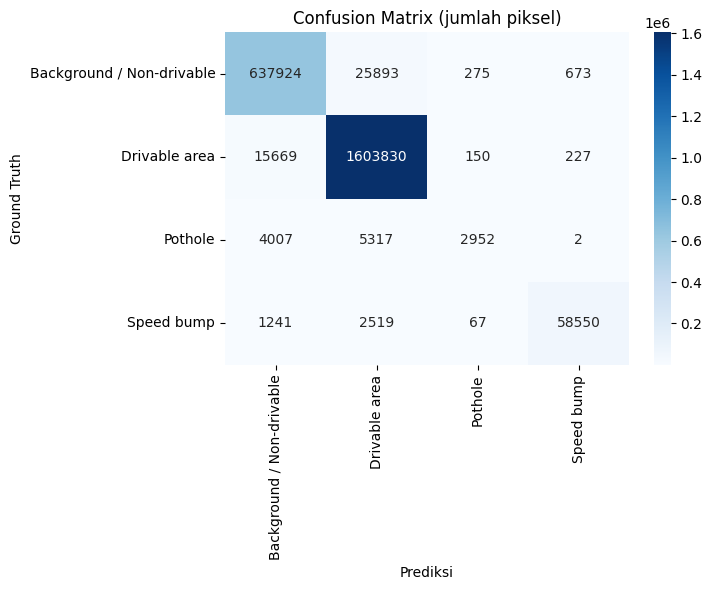

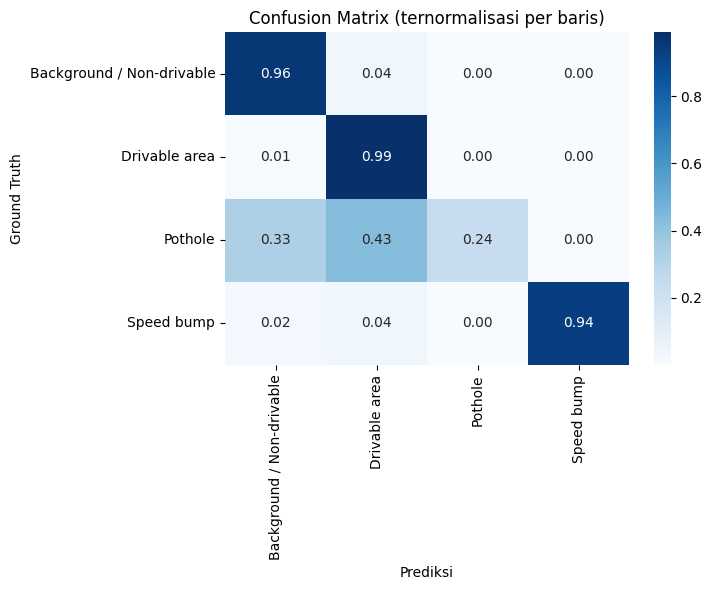

In [10]:
def plot_cm(matrix, title, fmt, fname):
    fig, ax = plt.subplots(figsize=(7.5, 6))
    if HAS_SNS:
        sns.heatmap(matrix, annot=True, fmt=fmt, cmap='Blues',
                    xticklabels=DISPLAY_NAMES, yticklabels=DISPLAY_NAMES, cbar=True, ax=ax)
    else:
        im = ax.imshow(matrix, cmap='Blues'); fig.colorbar(im, ax=ax)
        ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(DISPLAY_NAMES, rotation=45, ha='right')
        ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(DISPLAY_NAMES)
        thresh = matrix.max() / 2.0 if matrix.max() > 0 else 0.5
        for r in range(NUM_CLASSES):
            for cc in range(NUM_CLASSES):
                ax.text(cc, r, format(matrix[r, cc], fmt), ha='center', va='center',
                        color='white' if matrix[r, cc] > thresh else 'black')
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Ground Truth'); ax.set_title(title)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()

plot_cm(conf_mat, 'Confusion Matrix (jumlah piksel)', 'd', 'confusion_matrix_counts.png')

row_sums = conf_mat.sum(axis=1, keepdims=True)
cm_norm = conf_mat / np.maximum(row_sums, 1)
plot_cm(cm_norm, 'Confusion Matrix (ternormalisasi per baris)', '.2f', 'confusion_matrix_normalized.png')

## ✅ Selesai

File tersimpan di `/kaggle/working`:
- `metrik_per_kelas.csv`
- `ringkasan_metrik.csv`
- `confusion_matrix_counts.png`
- `confusion_matrix_normalized.png`

### Checklist sebelum run
1. Set `MODEL_PATH`, `CONFIG_PATH`, `IMAGES_DIR`, `MASKS_DIR`.
2. Pastikan urutan `DISPLAY_NAMES` sesuai index label di mask (0..3).
3. Bila mask berupa warna RGB, tambahkan mapping warna→index di `load_mask()`.
4. Set `IGNORE_INDEX` bila ada label void.